# v4 평가 분석 (3팀)

세션 49 시점에서 v4 학습 결과 분석.

**비교 대상**:
- baseline (e15): 합성 통합본 실패 모델 — 참고용
- v2 (e14): 합성 v2 (처방 1+2+3 적용), Top-1 31.9% / Top-3 53.2% / Det 95.7% / FP 100
- v3 (e11): 합성 v3 (palm 마스크 + 처방 4 일부), Top-1 29.8% / Top-3 55.3% / Det 93.6% / FP 99
- v4 (e??): 합성 v3 그대로 + 학습 사양 7개 변경 (imgsz 1536, EMA 0.0001, RandomCrop 1280, CachedMixUp 0.7, Albu 4종)

**핵심 비교**:
- v2+v3 ensemble (세션 48 측정): Top-1 36.2% — 현재 측정 최고치
- v4 단독 vs v2+v3 ensemble vs v2+v3+v4 ensemble — 최종 모델 결정

**시나리오 분기**:
| v4 단독 결과 | 결정 |
|---|---|
| Top-1 ≥ 33% | v4 채택 + v2+v3+v4 ensemble 시도 |
| Top-1 30~33% | v2+v3 ensemble 채택 (또는 4-way 더 나으면 그것) |
| Top-1 < 30% | v2 단독 + conf 0.2 또는 0.3 |


## 1. 환경 셋업 + 재사용 함수

In [21]:
import json
import unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from collections import Counter, defaultdict

plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

# ────── 경로 ──────
EVAL_DIR        = Path(r'D:\pill_detection\eval')
BASELINE_RESULT = EVAL_DIR / 'rtmdet_tiny_synth_e15_seed100_results.json'  # 참고용
V2_RESULT       = EVAL_DIR / 'rtmdet_tiny_synth_e14_seed100_results.json'
V3_RESULT       = EVAL_DIR / 'rtmdet_tiny_synth_e11_seed100_results.json'

# ★ v4 학습 끝난 후 best_epoch 받으면 아래 한 줄 채우기 ★
V4_BEST_EPOCH = 13  # 예: 11, 12, 13
V4_RESULT = (EVAL_DIR / f'rtmdet_tiny_synth_v4_e{V4_BEST_EPOCH}_seed100_results.json') if V4_BEST_EPOCH else None

# v4 결과 파일명 패턴 모르면 자동 탐지 fallback
if V4_RESULT is None or not V4_RESULT.exists():
    candidates = sorted(EVAL_DIR.glob('*v4*results.json'))
    if candidates:
        V4_RESULT = candidates[-1]
        print(f'V4 자동 탐지: {V4_RESULT.name}')

FIG_DIR = Path(r'D:\pill_detection\analysis\figures_v4_eval')
FIG_DIR.mkdir(parents=True, exist_ok=True)

print(f'baseline (e15) 존재: {BASELINE_RESULT.exists()}')
print(f'v2 (e14) 존재:       {V2_RESULT.exists()}')
print(f'v3 (e11) 존재:       {V3_RESULT.exists()}')
print(f'v4 존재:             {V4_RESULT.exists() if V4_RESULT else False}')
print(f'FIG_DIR: {FIG_DIR}')


# ────── 학습 노트북 셀 34, 40에서 그대로 가져온 함수 ──────
def nfc(s):
    return unicodedata.normalize('NFC', s) if isinstance(s, str) else s


def iou_xyxy(b1, b2):
    x1, y1 = max(b1[0], b2[0]), max(b1[1], b2[1])
    x2, y2 = min(b1[2], b2[2]), min(b1[3], b2[3])
    inter = max(0, x2 - x1) * max(0, y2 - y1)
    a1 = (b1[2] - b1[0]) * (b1[3] - b1[1])
    a2 = (b2[2] - b2[0]) * (b2[3] - b2[1])
    return inter / (a1 + a2 - inter + 1e-9)


def evaluate_v4_json(output_json, iou_thr=0.5):
    """v4 형식 결과 JSON 채점 (학습 노트북 셀 40 동일)."""
    n_top1 = n_top3 = n_match = 0
    img_top1_full = img_top3_full = 0
    n_false_pos = 0
    total_gt = sum(len(r['gt_bboxes']) for r in output_json['results'])
    n_imgs = len(output_json['results'])

    if total_gt == 0:
        return None

    for r in output_json['results']:
        gts = r['gt_bboxes']
        preds = r['predictions']
        used = set()
        img_all_top1 = bool(gts)
        img_all_top3 = bool(gts)

        for gt in gts:
            best_iou, best_idx = 0.0, -1
            for j, p in enumerate(preds):
                if j in used:
                    continue
                i = iou_xyxy(gt['bbox'], p['bbox'])
                if i > best_iou:
                    best_iou, best_idx = i, j

            if best_iou >= iou_thr and best_idx >= 0:
                n_match += 1
                used.add(best_idx)
                top3 = [nfc(n) for n in preds[best_idx]['top3_class_name']]
                gt_name = nfc(gt['dl_name'])
                if top3 and top3[0] == gt_name:
                    n_top1 += 1
                else:
                    img_all_top1 = False
                if gt_name in top3:
                    n_top3 += 1
                else:
                    img_all_top3 = False
            else:
                img_all_top1 = False
                img_all_top3 = False

        if img_all_top1:
            img_top1_full += 1
        if img_all_top3:
            img_top3_full += 1
        n_false_pos += len(preds) - len(used)

    return {
        'detection_rate': n_match / total_gt,
        'top1_accuracy':  n_top1  / total_gt,
        'top3_accuracy':  n_top3  / total_gt,
        'image_top1':     img_top1_full / n_imgs,
        'image_top3':     img_top3_full / n_imgs,
        'n_top1': n_top1, 'n_top3': n_top3, 'n_match': n_match,
        'n_false_pos': n_false_pos, 'total_gt': total_gt, 'n_imgs': n_imgs,
    }


def filter_results(data, filename_set):
    return {**data, 'results': [r for r in data['results'] if r['filename'] in filename_set]}


print('함수 정의 완료: nfc / iou_xyxy / evaluate_v4_json / filter_results')


baseline (e15) 존재: True
v2 (e14) 존재:       True
v3 (e11) 존재:       True
v4 존재:             True
FIG_DIR: D:\pill_detection\analysis\figures_v4_eval
함수 정의 완료: nfc / iou_xyxy / evaluate_v4_json / filter_results


## 2. 데이터 로드 + 자체 채점

In [22]:
# 4-way 결과 JSON 로드 (baseline 참고용 + v2/v3/v4 본 비교)
with open(BASELINE_RESULT, encoding='utf-8') as f:
    baseline_data = json.load(f)
with open(V2_RESULT, encoding='utf-8') as f:
    v2_data = json.load(f)
with open(V3_RESULT, encoding='utf-8') as f:
    v3_data = json.load(f)

assert V4_RESULT and V4_RESULT.exists(), 'V4_RESULT 경로 미설정 또는 파일 없음 — V4_BEST_EPOCH 채우기'
with open(V4_RESULT, encoding='utf-8') as f:
    v4_data = json.load(f)

print(f"baseline: best_epoch={baseline_data['best_epoch']}, num_images={baseline_data['num_images']}, num_gt={baseline_data['num_gt_bboxes']}")
print(f"v2:       best_epoch={v2_data['best_epoch']}, num_images={v2_data['num_images']}, num_gt={v2_data['num_gt_bboxes']}")
print(f"v3:       best_epoch={v3_data['best_epoch']}, num_images={v3_data['num_images']}, num_gt={v3_data['num_gt_bboxes']}")
print(f"v4:       best_epoch={v4_data['best_epoch']}, num_images={v4_data['num_images']}, num_gt={v4_data['num_gt_bboxes']}")
print(f"v4:       ms_per_image={v4_data.get('ms_per_image', 'N/A')}")

# 자체검증 (v2/v3 박혀있는 값 일치 확인 + v4 본 측정)
b_metrics  = evaluate_v4_json(baseline_data)
v2_metrics = evaluate_v4_json(v2_data)
v3_metrics = evaluate_v4_json(v3_data)
v4_metrics = evaluate_v4_json(v4_data)

print(f"\n=== 자체검증 ===")
print(f"v2 Top-1: {v2_metrics['top1_accuracy']:.1%} (기록 31.9% — 일치 확인)")
print(f"v3 Top-1: {v3_metrics['top1_accuracy']:.1%} (기록 29.8% — 일치 확인)")
print(f"v4 Top-1: {v4_metrics['top1_accuracy']:.1%} ★ 본 측정")
print(f"v4 Top-3: {v4_metrics['top3_accuracy']:.1%}")
print(f"v4 Det:   {v4_metrics['detection_rate']:.1%}")
print(f"v4 FP:    {v4_metrics['n_false_pos']}")

# filename 일치 검증
files_b  = {r['filename'] for r in baseline_data['results']}
files_v2 = {r['filename'] for r in v2_data['results']}
files_v3 = {r['filename'] for r in v3_data['results']}
files_v4 = {r['filename'] for r in v4_data['results']}
assert files_v2 == files_v3 == files_v4 == files_b, '파일 불일치'
print(f"\n파일 일치: {len(files_v2)}장 동일")


baseline: best_epoch=15, num_images=33, num_gt=47
v2:       best_epoch=14, num_images=33, num_gt=47
v3:       best_epoch=11, num_images=33, num_gt=47
v4:       best_epoch=13, num_images=33, num_gt=47
v4:       ms_per_image=132.1

=== 자체검증 ===
v2 Top-1: 31.9% (기록 31.9% — 일치 확인)
v3 Top-1: 29.8% (기록 29.8% — 일치 확인)
v4 Top-1: 46.8% ★ 본 측정
v4 Top-3: 59.6%
v4 Det:   95.7%
v4 FP:    84

파일 일치: 33장 동일


## 3. 33장 환경 라벨 (진단 노트북 셀 19)

In [23]:
# 진단 노트북 셀 19 환경 라벨 그대로 (02 노트북 동일)
env_labels = {
    '게보린정 300mg_3.png': 'paper',
    '글리아타민연질캡슐.png': 'palm',
    '낙소졸정 500_20mg.png': 'palm',
    '넥시움정 40mg.png': 'cloth',
    '노바스크정 5mg.png': 'cloth',
    '놀텍정 10mg.png': 'palm',
    '디카테오정.png': 'palm',
    '라시도필캡슐(비매품).png': 'palm',
    '마이칼디정.png': 'paper',
    '맥시부펜이알정.png': 'paper',
    '뮤테란캡슐 100mg.png': 'bottle',
    '비모보정 500_20mg.png': 'palm',
    '비오플250캡슐.png': 'palm',
    '비타비백정(비타민).png': 'palm',
    '아보다트연질캡슐 0.5mg_1.png': 'palm',
    '아스피린프로텍트정100mg.png': 'palm',
    '아토르바정 10mg.png': 'cloth',
    '엔테론정 150mg.png': 'cloth',
    '울트라셋이알서방정.png': 'box',
    '인사돌플러스정 35mg_.png': 'palm',
    '인사돌플러스정.png': 'palm',
    '자누비아정 50mg.png': 'cloth',
    '자트랄엑스엘정 10mg.png': 'cloth',
    '졸로푸트정 100mg.png': 'paper',
    '종근당글리아티린연질캡슐.png': 'dark',
    '지르텍정(세티리진염산염).png': 'palm',
    '지르텍정.png': 'desk',
    '케이캡정 50mg.png': 'desk',
    '쿠에타핀정 25mg.png': 'desk',
    '타이레놀500mg.png': 'palm',
    '타이레놀이알서방정(아세트아미노펜)(수출용).png': 'palm',
    '트루비타정 60mg.png': 'bottle',
    '프로스카정.png': 'desk',
}

# 라벨 매칭 검증
missing = files_v2 - set(env_labels.keys())
extra   = set(env_labels.keys()) - files_v2
assert not missing and not extra, f'missing={missing}, extra={extra}'
print(f'라벨 매칭 OK: {len(env_labels)} 파일')

# GT 박스 단위 환경 분포
env_gt_count = {}
for r in v2_data['results']:
    env = env_labels[r['filename']]
    env_gt_count[env] = env_gt_count.get(env, 0) + len(r['gt_bboxes'])

print(f'\n=== GT 박스 단위 환경 분포 ===')
for env in ['paper', 'bottle', 'cloth', 'palm', 'desk', 'dark', 'box']:
    n = env_gt_count.get(env, 0)
    print(f'  {env:8s}: {n}개')
print(f'  합계      : {sum(env_gt_count.values())}개 (기록: 47)')


라벨 매칭 OK: 33 파일

=== GT 박스 단위 환경 분포 ===
  paper   : 7개
  bottle  : 2개
  cloth   : 10개
  palm    : 20개
  desk    : 5개
  dark    : 2개
  box     : 1개
  합계      : 47개 (기록: 47)


## 4. 4-way 메인 비교표 + verdict 매트릭스

In [24]:
# ────── 메인 비교표 (4-way) ──────
print(f"=== 메인 비교표 (33장, 47 GT) ===")
print(f"{'측정':<20s} {'baseline':>10s} {'v2':>10s} {'v3':>10s} {'v4':>10s}")
print('-' * 65)
for label, key in [('Top-1', 'top1_accuracy'), ('Top-3', 'top3_accuracy'),
                    ('Detection', 'detection_rate'),
                    ('Image Top-1', 'image_top1'), ('Image Top-3', 'image_top3')]:
    print(f"{label:<20s} {b_metrics[key]:>9.1%} {v2_metrics[key]:>9.1%} {v3_metrics[key]:>9.1%} {v4_metrics[key]:>9.1%}")
print(f"{'False Positive':<20s} {b_metrics['n_false_pos']:>10d} {v2_metrics['n_false_pos']:>10d} {v3_metrics['n_false_pos']:>10d} {v4_metrics['n_false_pos']:>10d}")
print(f"{'best_epoch':<20s} {baseline_data['best_epoch']:>10d} {v2_data['best_epoch']:>10d} {v3_data['best_epoch']:>10d} {v4_data['best_epoch']:>10d}")
print(f"{'ms/image':<20s} {baseline_data.get('ms_per_image', 0):>10.1f} {v2_data.get('ms_per_image', 0):>10.1f} {v3_data.get('ms_per_image', 0):>10.1f} {v4_data.get('ms_per_image', 0):>10.1f}")


# ────── 47 GT 단위 verdict 매칭 ──────
def get_verdict_per_gt(data, iou_thr=0.5):
    """{(filename, gt_idx): verdict} 반환."""
    result = {}
    for r in data['results']:
        used = set()
        for gt_idx, gt in enumerate(r['gt_bboxes']):
            best_iou, best_idx = 0.0, -1
            for j, p in enumerate(r['predictions']):
                if j in used:
                    continue
                i = iou_xyxy(gt['bbox'], p['bbox'])
                if i > best_iou:
                    best_iou, best_idx = i, j
            if best_iou < iou_thr or best_idx < 0:
                verdict = 'det_fail'
            else:
                used.add(best_idx)
                top3 = [nfc(n) for n in r['predictions'][best_idx]['top3_class_name']]
                gt_name = nfc(gt['dl_name'])
                if top3 and top3[0] == gt_name:
                    verdict = 'top1'
                elif gt_name in top3:
                    verdict = 'top3'
                else:
                    verdict = 'wrong'
            result[(r['filename'], gt_idx)] = verdict
    return result


v2_verdicts = get_verdict_per_gt(v2_data)
v3_verdicts = get_verdict_per_gt(v3_data)
v4_verdicts = get_verdict_per_gt(v4_data)


# ────── verdict 분포 비교 ──────
def verdict_dist(verdicts):
    c = Counter(verdicts.values())
    total = sum(c.values())
    return {v: c.get(v, 0) for v in ['top1', 'top3', 'wrong', 'det_fail']}, total


print(f"\n=== verdict 분포 (47 GT) ===")
print(f"{'verdict':<12s} {'v2':>8s} {'v3':>8s} {'v4':>8s}")
print('-' * 42)
v2_dist, _ = verdict_dist(v2_verdicts)
v3_dist, _ = verdict_dist(v3_verdicts)
v4_dist, _ = verdict_dist(v4_verdicts)
for v in ['top1', 'top3', 'wrong', 'det_fail']:
    print(f"{v:<12s} {v2_dist[v]:>8d} {v3_dist[v]:>8d} {v4_dist[v]:>8d}")


# ────── v2 → v4 verdict transition 매트릭스 ──────
print(f"\n=== v2 → v4 verdict 변화 매트릭스 (행: v2, 열: v4) ===")
order = ['top1', 'top3', 'wrong', 'det_fail']
matrix = {v2v: {v4v: 0 for v4v in order} for v2v in order}
for k in v2_verdicts:
    matrix[v2_verdicts[k]][v4_verdicts[k]] += 1

header_label = 'v2 \\ v4'
print(f"{header_label:<12s}" + ''.join(f"{v:>10s}" for v in order))
print('-' * 55)
for v2v in order:
    row = [matrix[v2v][v4v] for v4v in order]
    print(f"{v2v:<12s}" + ''.join(f"{v:>10d}" for v in row))


# 회복/후퇴 케이스 요약
rank = {'det_fail': 0, 'wrong': 1, 'top3': 2, 'top1': 3}
recovered_v4 = sum(1 for k in v2_verdicts if rank[v4_verdicts[k]] > rank[v2_verdicts[k]])
regressed_v4 = sum(1 for k in v2_verdicts if rank[v4_verdicts[k]] < rank[v2_verdicts[k]])
print(f"\nv2 → v4 회복: {recovered_v4}건 / 후퇴: {regressed_v4}건 (순증 {recovered_v4-regressed_v4}건)")


=== 메인 비교표 (33장, 47 GT) ===
측정                     baseline         v2         v3         v4
-----------------------------------------------------------------
Top-1                    29.8%     31.9%     29.8%     46.8%
Top-3                    40.4%     53.2%     55.3%     59.6%
Detection                95.7%     95.7%     93.6%     95.7%
Image Top-1              27.3%     24.2%     27.3%     42.4%
Image Top-3              36.4%     48.5%     48.5%     54.5%
False Positive              259        100         99         84
best_epoch                   15         14         11         13
ms/image                  125.5      128.6      132.1      132.1

=== verdict 분포 (47 GT) ===
verdict            v2       v3       v4
------------------------------------------
top1               15       14       22
top3               10       12        6
wrong              20       18       17
det_fail            2        3        2

=== v2 → v4 verdict 변화 매트릭스 (행: v2, 열: v4) ===
v2 \ v4           top1

## 5. 3-way 환경별 비교 (v2 / v3 / v4)

In [25]:
def env_breakdown(data, env_labels, iou_thr=0.5):
    """환경별 Top-1, Top-3, Detection rate 계산 (GT 박스 단위)."""
    env_stats = {}
    for r in data['results']:
        env = env_labels[r['filename']]
        if env not in env_stats:
            env_stats[env] = {'n_gt': 0, 'n_top1': 0, 'n_top3': 0, 'n_match': 0}
        gts = r['gt_bboxes']
        preds = r['predictions']
        used = set()
        for gt in gts:
            env_stats[env]['n_gt'] += 1
            best_iou, best_idx = 0.0, -1
            for j, p in enumerate(preds):
                if j in used:
                    continue
                i = iou_xyxy(gt['bbox'], p['bbox'])
                if i > best_iou:
                    best_iou, best_idx = i, j
            if best_iou >= iou_thr and best_idx >= 0:
                env_stats[env]['n_match'] += 1
                used.add(best_idx)
                top3 = [nfc(n) for n in preds[best_idx]['top3_class_name']]
                gt_name = nfc(gt['dl_name'])
                if top3 and top3[0] == gt_name:
                    env_stats[env]['n_top1'] += 1
                elif gt_name in top3:
                    env_stats[env]['n_top3'] += 1
    return env_stats


v2_env = env_breakdown(v2_data, env_labels)
v3_env = env_breakdown(v3_data, env_labels)
v4_env = env_breakdown(v4_data, env_labels)


print(f"=== 환경별 Top-1 (47 GT) ===")
print(f"{'환경':8s} {'n':>4s} | {'v2':>9s} {'v3':>9s} {'v4':>9s} | {'v3-v2':>8s} {'v4-v2':>8s} {'v4-v3':>8s}")
print('-' * 90)

env_order = ['paper', 'bottle', 'cloth', 'palm', 'desk', 'dark', 'box']
for env in env_order:
    if env not in v2_env:
        continue
    n = v2_env[env]['n_gt']
    v2_t1 = v2_env[env]['n_top1'] / n
    v3_t1 = v3_env[env]['n_top1'] / n
    v4_t1 = v4_env[env]['n_top1'] / n
    print(f"{env:8s} {n:>4d} | {v2_t1:>8.1%}  {v3_t1:>8.1%}  {v4_t1:>8.1%} | "
          f"{(v3_t1-v2_t1)*100:>+7.1f}pp {(v4_t1-v2_t1)*100:>+7.1f}pp {(v4_t1-v3_t1)*100:>+7.1f}pp")


print(f"\n=== 환경별 Top-3 누적 (47 GT) ===")
print(f"{'환경':8s} {'n':>4s} | {'v2':>9s} {'v3':>9s} {'v4':>9s} | {'v3-v2':>8s} {'v4-v2':>8s} {'v4-v3':>8s}")
print('-' * 90)
for env in env_order:
    if env not in v2_env:
        continue
    n = v2_env[env]['n_gt']
    v2_t3 = (v2_env[env]['n_top1'] + v2_env[env]['n_top3']) / n
    v3_t3 = (v3_env[env]['n_top1'] + v3_env[env]['n_top3']) / n
    v4_t3 = (v4_env[env]['n_top1'] + v4_env[env]['n_top3']) / n
    print(f"{env:8s} {n:>4d} | {v2_t3:>8.1%}  {v3_t3:>8.1%}  {v4_t3:>8.1%} | "
          f"{(v3_t3-v2_t3)*100:>+7.1f}pp {(v4_t3-v2_t3)*100:>+7.1f}pp {(v4_t3-v3_t3)*100:>+7.1f}pp")


# ────── 가설 검증 (v4) ──────
print(f"\n=== v4 처방 효과 검증 (palm/dark/paper) ===")
for env, target in [('palm', 0.40), ('dark', 0.20), ('paper', 0.30)]:
    if env not in v4_env:
        continue
    n = v2_env[env]['n_gt']
    v2_t1 = v2_env[env]['n_top1'] / n
    v3_t1 = v3_env[env]['n_top1'] / n
    v4_t1 = v4_env[env]['n_top1'] / n
    ok = '✓' if v4_t1 >= target else '✗'
    print(f"{env:6s}: v2={v2_t1:.1%} → v3={v3_t1:.1%} → v4={v4_t1:.1%} (목표 {target:.0%}, {ok})")


=== 환경별 Top-1 (47 GT) ===
환경          n |        v2        v3        v4 |    v3-v2    v4-v2    v4-v3
------------------------------------------------------------------------------------------
paper       7 |    28.6%     14.3%     42.9% |   -14.3pp   +14.3pp   +28.6pp
bottle      2 |   100.0%    100.0%    100.0% |    +0.0pp    +0.0pp    +0.0pp
cloth      10 |    40.0%     30.0%     40.0% |   -10.0pp    +0.0pp   +10.0pp
palm       20 |    30.0%     35.0%     50.0% |    +5.0pp   +20.0pp   +15.0pp
desk        5 |    20.0%     20.0%     40.0% |    +0.0pp   +20.0pp   +20.0pp
dark        2 |     0.0%      0.0%     50.0% |    +0.0pp   +50.0pp   +50.0pp
box         1 |     0.0%      0.0%      0.0% |    +0.0pp    +0.0pp    +0.0pp

=== 환경별 Top-3 누적 (47 GT) ===
환경          n |        v2        v3        v4 |    v3-v2    v4-v2    v4-v3
------------------------------------------------------------------------------------------
paper       7 |    28.6%     42.9%     57.1% |   +14.3pp   +28.6pp   +14.

## 6. Hallucination 3-way 분포

33장 GT 정답 클래스 (unique): 31개

=== Hallucination Top 12 (3-way 비교) ===
클래스                                 v2    v3    v4    v4-v2
-----------------------------------------------------------------
프로스카정                                5     0     5       +0
아빌리파이정 10mg                          0     2     5       +5
엘도스캡슐(에르도스테인)(수출용)                   7     0     5       -2
씨즈날정(세티리진염산염)                        1     7     4       +3
일양하이트린정 2mg                          1     7     2       +1
아모잘탄정 5/100mg                        1     6     1       +0
엔트레스토필름코팅정 200mg                     1     5     1       +0
투스딘골드캡슐 150mg/PTP                    5     0     1       -4
이튼큐정 35mg/PTP                        6     0     0       -6
플라빅스정 75mg                           1     6     0       -1
동화덴스톨캡슐 150mg/PTP                    6     1     0       -6

=== Hallucination 합계 ===
v2: 91회
v3: 91회
v4: 71회 (-20 vs v2)


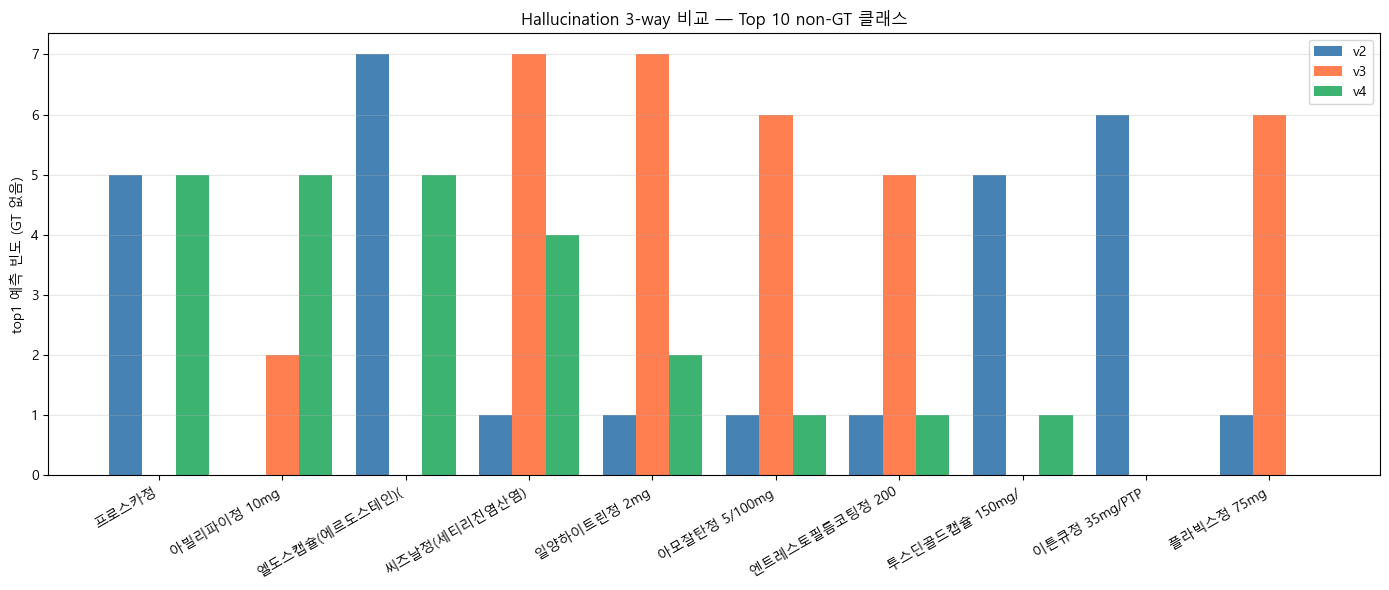

저장: D:\pill_detection\analysis\figures_v4_eval\hallucination_3way.png


In [26]:
# 33장 GT 정답 클래스 집합
gt_classes = set()
for r in v2_data['results']:
    for gt in r['gt_bboxes']:
        gt_classes.add(nfc(gt['dl_name']))
print(f'33장 GT 정답 클래스 (unique): {len(gt_classes)}개')


def collect_top1_predictions(data):
    counter = Counter()
    for r in data['results']:
        for pred in r['predictions']:
            top1 = nfc(pred['top3_class_name'][0])
            counter[top1] += 1
    return counter


v2_top1_cnt = collect_top1_predictions(v2_data)
v3_top1_cnt = collect_top1_predictions(v3_data)
v4_top1_cnt = collect_top1_predictions(v4_data)

# 합집합 — non-GT 클래스 중 어디서든 5회 이상 나온 것
all_non_gt = set()
for cnt in [v2_top1_cnt, v3_top1_cnt, v4_top1_cnt]:
    for cls, n in cnt.items():
        if cls not in gt_classes and n >= 5:
            all_non_gt.add(cls)

# 정렬 (v4 빈도 기준)
sorted_non_gt = sorted(all_non_gt, key=lambda c: -v4_top1_cnt.get(c, 0))

print(f'\n=== Hallucination Top 12 (3-way 비교) ===')
print(f"{'클래스':<32s} {'v2':>5s} {'v3':>5s} {'v4':>5s} {'v4-v2':>8s}")
print('-' * 65)
for cls in sorted_non_gt[:12]:
    v2_n = v2_top1_cnt.get(cls, 0)
    v3_n = v3_top1_cnt.get(cls, 0)
    v4_n = v4_top1_cnt.get(cls, 0)
    print(f"{cls[:30]:<32s} {v2_n:>5d} {v3_n:>5d} {v4_n:>5d} {v4_n-v2_n:>+8d}")

# 합계
v2_halluc_total = sum(n for cls, n in v2_top1_cnt.items() if cls not in gt_classes)
v3_halluc_total = sum(n for cls, n in v3_top1_cnt.items() if cls not in gt_classes)
v4_halluc_total = sum(n for cls, n in v4_top1_cnt.items() if cls not in gt_classes)
print(f'\n=== Hallucination 합계 ===')
print(f'v2: {v2_halluc_total}회')
print(f'v3: {v3_halluc_total}회')
print(f'v4: {v4_halluc_total}회 ({v4_halluc_total-v2_halluc_total:+d} vs v2)')


# ────── 시각화 ──────
top10 = sorted_non_gt[:10]
v2_v = [v2_top1_cnt.get(c, 0) for c in top10]
v3_v = [v3_top1_cnt.get(c, 0) for c in top10]
v4_v = [v4_top1_cnt.get(c, 0) for c in top10]

x = np.arange(len(top10))
w = 0.27
fig, ax = plt.subplots(figsize=(14, 6))
ax.bar(x - w, v2_v, w, label='v2', color='steelblue')
ax.bar(x,     v3_v, w, label='v3', color='coral')
ax.bar(x + w, v4_v, w, label='v4', color='mediumseagreen')
ax.set_xticks(x)
ax.set_xticklabels([c[:14] for c in top10], rotation=30, ha='right')
ax.set_ylabel('top1 예측 빈도 (GT 없음)')
ax.set_title('Hallucination 3-way 비교 — Top 10 non-GT 클래스')
ax.legend()
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
out_path = FIG_DIR / 'hallucination_3way.png'
plt.savefig(out_path, dpi=120, bbox_inches='tight')
plt.show()
print(f'저장: {out_path}')


## 7. conf threshold sweep (3-way)

=== conf threshold sweep (47 GT, 3-way) ===
  conf |   v2 T1   v2 T3  v2 FP |   v3 T1   v3 T3  v3 FP |   v4 T1   v4 T3  v4 FP
----------------------------------------------------------------------------------------------------
  0.05 |  31.9%  53.2%    100 |  29.8%  55.3%     99 |  46.8%  59.6%     84
  0.10 |  31.9%  53.2%     54 |  29.8%  55.3%     48 |  46.8%  59.6%     29
  0.15 |  31.9%  53.2%     39 |  29.8%  55.3%     28 |  46.8%  59.6%     20
  0.20 |  31.9%  53.2%     26 |  29.8%  55.3%     21 |  46.8%  59.6%     14
  0.25 |  31.9%  53.2%     19 |  29.8%  55.3%     16 |  46.8%  59.6%     10
  0.30 |  31.9%  53.2%     13 |  29.8%  53.2%     14 |  44.7%  57.4%      7
  0.40 |  31.9%  51.1%      3 |  29.8%  53.2%      4 |  44.7%  55.3%      2


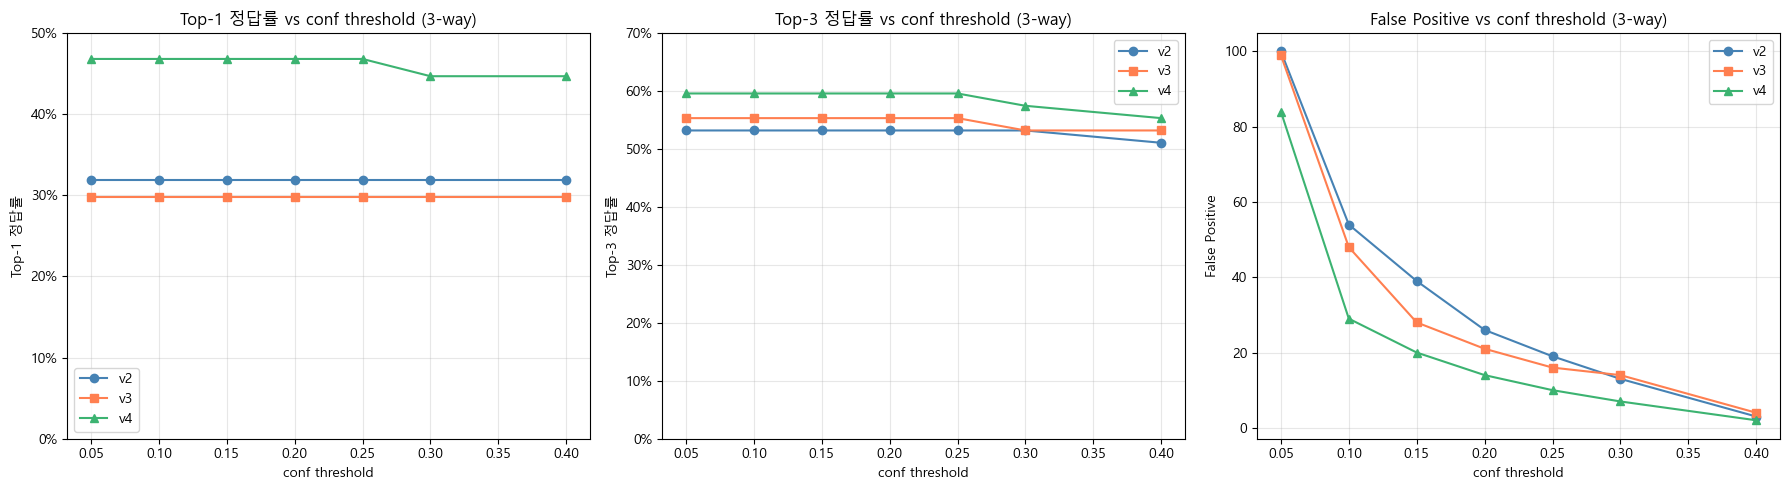

저장: D:\pill_detection\analysis\figures_v4_eval\conf_threshold_sweep_3way.png


In [27]:
def evaluate_with_conf_threshold(data, conf_thr=0.05, iou_thr=0.5):
    n_top1 = n_top3 = n_match = n_false_pos = 0
    total_gt = sum(len(r['gt_bboxes']) for r in data['results'])
    for r in data['results']:
        preds = [p for p in r['predictions'] if p['top3_confidence'][0] >= conf_thr]
        used = set()
        for gt in r['gt_bboxes']:
            best_iou, best_idx = 0.0, -1
            for j, p in enumerate(preds):
                if j in used:
                    continue
                i = iou_xyxy(gt['bbox'], p['bbox'])
                if i > best_iou:
                    best_iou, best_idx = i, j
            if best_iou >= iou_thr and best_idx >= 0:
                n_match += 1
                used.add(best_idx)
                top3 = [nfc(n) for n in preds[best_idx]['top3_class_name']]
                gt_name = nfc(gt['dl_name'])
                if top3 and top3[0] == gt_name:
                    n_top1 += 1
                if gt_name in top3:
                    n_top3 += 1
        n_false_pos += len(preds) - len(used)
    return {'top1': n_top1/total_gt, 'top3': n_top3/total_gt,
            'det': n_match/total_gt, 'fp': n_false_pos}


conf_levels = [0.05, 0.10, 0.15, 0.20, 0.25, 0.30, 0.40]

print(f"=== conf threshold sweep (47 GT, 3-way) ===")
print(f"{'conf':>6s} | {'v2 T1':>7s} {'v2 T3':>7s} {'v2 FP':>6s} | "
      f"{'v3 T1':>7s} {'v3 T3':>7s} {'v3 FP':>6s} | "
      f"{'v4 T1':>7s} {'v4 T3':>7s} {'v4 FP':>6s}")
print('-' * 100)

sweep_v2 = {c: evaluate_with_conf_threshold(v2_data, c) for c in conf_levels}
sweep_v3 = {c: evaluate_with_conf_threshold(v3_data, c) for c in conf_levels}
sweep_v4 = {c: evaluate_with_conf_threshold(v4_data, c) for c in conf_levels}

for c in conf_levels:
    a, b, d = sweep_v2[c], sweep_v3[c], sweep_v4[c]
    print(f"{c:>6.2f} | {a['top1']:>6.1%} {a['top3']:>6.1%} {a['fp']:>6d} | "
          f"{b['top1']:>6.1%} {b['top3']:>6.1%} {b['fp']:>6d} | "
          f"{d['top1']:>6.1%} {d['top3']:>6.1%} {d['fp']:>6d}")


# ────── 시각화 ──────
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax_idx, (metric, ylabel, ylim) in enumerate([
    ('top1', 'Top-1 정답률', (0, 0.5)),
    ('top3', 'Top-3 정답률', (0, 0.7)),
    ('fp', 'False Positive', None),
]):
    ax = axes[ax_idx]
    ax.plot(conf_levels, [sweep_v2[c][metric] for c in conf_levels], 'o-', label='v2', color='steelblue')
    ax.plot(conf_levels, [sweep_v3[c][metric] for c in conf_levels], 's-', label='v3', color='coral')
    ax.plot(conf_levels, [sweep_v4[c][metric] for c in conf_levels], '^-', label='v4', color='mediumseagreen')
    ax.set_xlabel('conf threshold')
    ax.set_ylabel(ylabel)
    ax.set_title(f'{ylabel} vs conf threshold (3-way)')
    ax.legend()
    ax.grid(alpha=0.3)
    if ylim:
        ax.set_ylim(*ylim)
    if metric in ('top1', 'top3'):
        ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.0%}'))

plt.tight_layout()
out_path = FIG_DIR / 'conf_threshold_sweep_3way.png'
plt.savefig(out_path, dpi=120, bbox_inches='tight')
plt.show()
print(f'저장: {out_path}')


## 8. Ensemble 4-way 비교 (v2+v3 / v2+v4 / v3+v4 / v2+v3+v4)

세션 48에서 v2+v3 ensemble Top-1 36.2% 측정. v4 추가하면 더 올라가는지 검증.

방식: IoU 매칭 후 conf 평균 (방식 A) — 모든 모델의 prediction을 IoU 0.5 기준으로 매칭, 매칭된 그룹은 bbox 평균 + top3 클래스 conf 합산 후 재선정. unique prediction은 conf threshold 통과 시 유지.

=== Ensemble 4-way 비교 (47 GT, conf 0.2) ===
방식                              Top-1    Top-3      Det    FP
-----------------------------------------------------------------
v2 단독 (conf 0.2)               31.9%   53.2%   95.7%    26
v3 단독 (conf 0.2)               29.8%   55.3%   93.6%    21
v4 단독 (conf 0.2)               46.8%   59.6%   95.7%    14
v2+v3 ensemble                 36.2%   55.3%   95.7%    33
v2+v4 ensemble                 44.7%   57.4%   95.7%    28
v3+v4 ensemble                 44.7%   61.7%   95.7%    24
v2+v3+v4 ensemble              42.6%   57.4%   95.7%    35


C:\Users\tran6\AppData\Local\Temp\ipykernel_9284\4166209723.py:153: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(labels, rotation=20, ha='right')


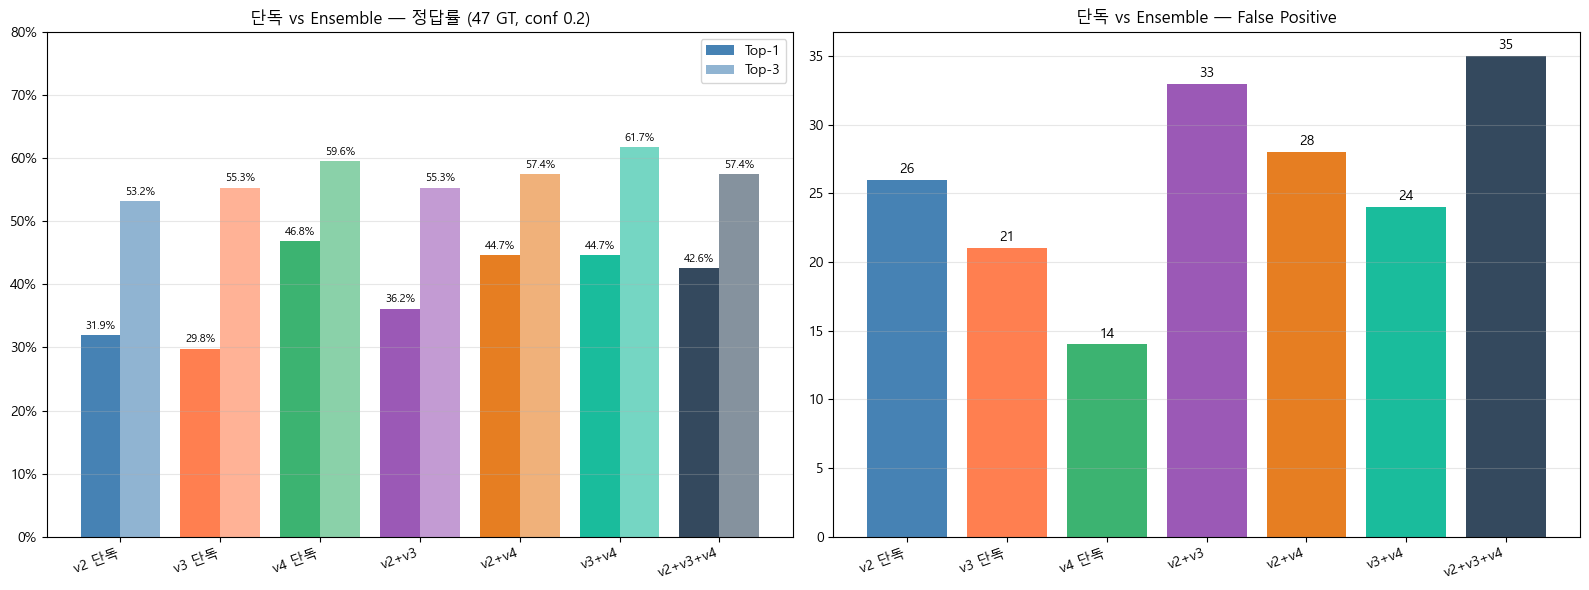

저장: D:\pill_detection\analysis\figures_v4_eval\ensemble_4way_comparison.png

=== 최고 성능 ===
방식: v4 단독 (conf 0.2)
Top-1 46.8% / Top-3 59.6% / Det 95.7% / FP 14


In [28]:
def merge_predictions_nway(pred_lists, conf_thr=0.2, iou_match=0.5):
    """N-way ensemble (세션 48 방식 A 일반화).
    pred_lists: [v2_preds, v3_preds, v4_preds] 등 모델별 prediction 리스트의 리스트.
    각 prediction은 {bbox, top3_class_name, top3_confidence} 형식.
    """
    # 1) 각 모델별 conf threshold 통과 prediction
    filtered = [[p for p in preds if p['top3_confidence'][0] >= conf_thr]
                for preds in pred_lists]

    # 2) 첫 모델을 base로, 다른 모델들의 prediction을 IoU로 그룹화
    if not filtered or not filtered[0]:
        # base가 비어있으면 다른 모델 prediction을 그대로 사용
        merged = []
        for preds in filtered:
            merged.extend(preds)
        return merged

    n_models = len(filtered)
    used = [set() for _ in range(n_models)]  # 각 모델별 사용된 idx
    merged = []

    for i, base_pred in enumerate(filtered[0]):
        # base에서 매칭 그룹 시작
        group = [base_pred]
        used[0].add(i)
        # 다른 모델들에서 IoU 매칭 찾기
        for m_idx in range(1, n_models):
            best_iou, best_j = 0.0, -1
            for j, p in enumerate(filtered[m_idx]):
                if j in used[m_idx]:
                    continue
                iou = iou_xyxy(base_pred['bbox'], p['bbox'])
                if iou > best_iou:
                    best_iou, best_j = iou, j
            if best_iou >= iou_match and best_j >= 0:
                group.append(filtered[m_idx][best_j])
                used[m_idx].add(best_j)

        # 그룹 통합: bbox 평균 + top3 conf 합산
        avg_bbox = [sum(p['bbox'][k] for p in group) / len(group) for k in range(4)]
        conf_acc = {}
        for p in group:
            for cls, c in zip(p['top3_class_name'], p['top3_confidence']):
                cls_n = nfc(cls)
                conf_acc[cls_n] = conf_acc.get(cls_n, 0) + c
        top3_sorted = sorted(conf_acc.items(), key=lambda x: -x[1])[:3]
        merged.append({
            'bbox': avg_bbox,
            'top3_class_name': [c for c, _ in top3_sorted],
            'top3_confidence': [c / len(group) for _, c in top3_sorted],
        })

    # 3) base에 매칭 안 된 다른 모델들의 prediction은 그대로 추가
    for m_idx in range(1, n_models):
        for j, p in enumerate(filtered[m_idx]):
            if j not in used[m_idx]:
                merged.append(p)

    return merged


def evaluate_ensemble_nway(data_list, merge_fn, conf_thr=0.2, iou_thr=0.5):
    """N개 모델 데이터를 ensemble 후 채점."""
    n_top1 = n_top3 = n_match = n_false_pos = 0
    base = data_list[0]
    total_gt = sum(len(r['gt_bboxes']) for r in base['results'])
    other_maps = [{r['filename']: r for r in d['results']} for d in data_list[1:]]

    for r in base['results']:
        pred_lists = [r['predictions']] + [m[r['filename']]['predictions'] for m in other_maps]
        merged = merge_fn(pred_lists, conf_thr=conf_thr)

        used = set()
        for gt in r['gt_bboxes']:
            best_iou, best_idx = 0.0, -1
            for j, p in enumerate(merged):
                if j in used:
                    continue
                i = iou_xyxy(gt['bbox'], p['bbox'])
                if i > best_iou:
                    best_iou, best_idx = i, j
            if best_iou >= iou_thr and best_idx >= 0:
                n_match += 1
                used.add(best_idx)
                top3 = [nfc(n) for n in merged[best_idx]['top3_class_name']]
                gt_name = nfc(gt['dl_name'])
                if top3 and top3[0] == gt_name:
                    n_top1 += 1
                if gt_name in top3:
                    n_top3 += 1
        n_false_pos += len(merged) - len(used)

    return {'top1': n_top1/total_gt, 'top3': n_top3/total_gt,
            'det': n_match/total_gt, 'fp': n_false_pos}


# ────── 4-way ensemble 비교 ──────
configs = [
    ('v2 단독 (conf 0.2)',       [v2_data]),
    ('v3 단독 (conf 0.2)',       [v3_data]),
    ('v4 단독 (conf 0.2)',       [v4_data]),
    ('v2+v3 ensemble',           [v2_data, v3_data]),
    ('v2+v4 ensemble',           [v2_data, v4_data]),
    ('v3+v4 ensemble',           [v3_data, v4_data]),
    ('v2+v3+v4 ensemble',        [v2_data, v3_data, v4_data]),
]

results = []
for name, data_list in configs:
    if len(data_list) == 1:
        m = evaluate_with_conf_threshold(data_list[0], conf_thr=0.2)
    else:
        m = evaluate_ensemble_nway(data_list, merge_predictions_nway, conf_thr=0.2)
    results.append((name, m))

print(f"=== Ensemble 4-way 비교 (47 GT, conf 0.2) ===")
print(f"{'방식':<28s} {'Top-1':>8s} {'Top-3':>8s} {'Det':>8s} {'FP':>5s}")
print('-' * 65)
for name, m in results:
    print(f"{name:<28s} {m['top1']:>7.1%} {m['top3']:>7.1%} {m['det']:>7.1%} {m['fp']:>5d}")


# ────── 시각화 (보고서/발표용) ──────
labels = [name.replace(' (conf 0.2)', '').replace(' ensemble', '') for name, _ in results]
top1_vals = [m['top1'] for _, m in results]
top3_vals = [m['top3'] for _, m in results]
fp_vals   = [m['fp']   for _, m in results]
colors = ['steelblue', 'coral', 'mediumseagreen', '#9b59b6', '#e67e22', '#1abc9c', '#34495e']

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
x = np.arange(len(labels))

# Top-1 / Top-3
ax = axes[0]
w = 0.4
ax.bar(x - w/2, top1_vals, w, label='Top-1', color=colors)
ax.bar(x + w/2, top3_vals, w, label='Top-3', color=colors, alpha=0.6)
ax.set_xticks(x)
ax.set_xticklabels(labels, rotation=20, ha='right')
ax.set_ylim(0, 0.8)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.0%}'))
ax.set_title('단독 vs Ensemble — 정답률 (47 GT, conf 0.2)')
ax.legend()
ax.grid(axis='y', alpha=0.3)
for i, v in enumerate(top1_vals):
    ax.text(i - w/2, v + 0.01, f'{v:.1%}', ha='center', fontsize=8)
for i, v in enumerate(top3_vals):
    ax.text(i + w/2, v + 0.01, f'{v:.1%}', ha='center', fontsize=8)

# FP
ax = axes[1]
bars = ax.bar(labels, fp_vals, color=colors)
ax.set_xticklabels(labels, rotation=20, ha='right')
ax.set_title('단독 vs Ensemble — False Positive')
ax.grid(axis='y', alpha=0.3)
for b, v in zip(bars, fp_vals):
    ax.text(b.get_x() + b.get_width()/2, v + 0.5, f'{v}', ha='center', fontsize=10)

plt.tight_layout()
out_path = FIG_DIR / 'ensemble_4way_comparison.png'
plt.savefig(out_path, dpi=120, bbox_inches='tight')
plt.show()
print(f'저장: {out_path}')


# ────── 최고 성능 추출 ──────
best_idx = max(range(len(results)), key=lambda i: results[i][1]['top1'])
best_name, best_m = results[best_idx]
print(f"\n=== 최고 성능 ===")
print(f"방식: {best_name}")
print(f"Top-1 {best_m['top1']:.1%} / Top-3 {best_m['top3']:.1%} / Det {best_m['det']:.1%} / FP {best_m['fp']}")


## 9. 최종 모델 결정 + 권장 사양

핸드오프 시나리오 분기:
- v4 단독 Top-1 ≥ 33% → v4 채택 + v2+v3+v4 ensemble 시도
- v4 단독 Top-1 30~33% → v2+v3 ensemble 채택 (단 4-way가 더 나으면 그것)
- v4 단독 Top-1 < 30% → v2 단독 + conf 0.2 또는 0.3

In [29]:
# v4 단독 Top-1 기준 자동 분기
v4_top1 = v4_metrics['top1_accuracy']

print(f"=== v4 단독 결과 ===")
print(f"Top-1: {v4_top1:.1%}")
print(f"Top-3: {v4_metrics['top3_accuracy']:.1%}")
print(f"Det:   {v4_metrics['detection_rate']:.1%}")
print(f"FP:    {v4_metrics['n_false_pos']}")
print(f"best_epoch: {v4_data['best_epoch']}, ms/image: {v4_data.get('ms_per_image', 'N/A')}")

print(f"\n=== 시나리오 분기 ===")
if v4_top1 >= 0.33:
    print(f'시나리오 A: v4 채택 (Top-1 {v4_top1:.1%} ≥ 33%)')
    print('  → 후속: v4 데모 패키지 빌드 + 지우님 전달')
    print('  → ensemble 검토: v2+v3+v4 4-way가 v4 단독 대비 추가 이득 있는지 셀 16 결과 비교')
elif v4_top1 >= 0.30:
    print(f'시나리오 B: v2+v3 ensemble 채택 (v4 Top-1 {v4_top1:.1%}, 30~33%)')
    print('  → v4 결과와 4-way ensemble 결과 비교 후 더 나은 쪽 선택')
    print('  → 후속: ensemble 추론 코드 정리 + 지우님 전달')
else:
    print(f'시나리오 C: v2 단독 + conf 0.2~0.3 채택 (v4 Top-1 {v4_top1:.1%} < 30%)')
    print('  → 후속: conf 적용 코드 정리 + 지우님 전달')


# ────── 비교 후보 묶음 추천 ──────
top_candidates = sorted(results, key=lambda x: -x[1]['top1'])[:3]
print(f"\n=== Top-1 기준 상위 3개 후보 ===")
for i, (name, m) in enumerate(top_candidates, 1):
    print(f"{i}위. {name}: Top-1 {m['top1']:.1%} / Top-3 {m['top3']:.1%} / Det {m['det']:.1%} / FP {m['fp']}")


# ────── 권장 사양 출력 ──────
best_name, best_m = top_candidates[0]
print(f"\n=== 권장 사양 ===")
print(f'최종 모델: {best_name}')
print(f'성능:      Top-1 {best_m["top1"]:.1%} / Top-3 {best_m["top3"]:.1%} / Det {best_m["det"]:.1%} / FP {best_m["fp"]}')
print(f'추론 사양: conf 0.2, IoU 0.5, NMS post')
if 'ensemble' in best_name:
    print(f'ensemble 방식: IoU 매칭 후 conf 평균 (방식 A) — merge_predictions_nway 함수 사용')
    print(f'사용 모델 가중치:')
    if 'v2' in best_name:
        print(f'  - v2: D:\\seungwon_v6_work_dir\\best_coco_bbox_mAP_epoch_14.pth')
    if 'v3' in best_name:
        print(f'  - v3: (Drive 백업본 위치 확인 필요)')
    if 'v4' in best_name:
        print(f'  - v4: (Drive 백업본 위치 확인 필요)')


=== v4 단독 결과 ===
Top-1: 46.8%
Top-3: 59.6%
Det:   95.7%
FP:    84
best_epoch: 13, ms/image: 132.1

=== 시나리오 분기 ===
시나리오 A: v4 채택 (Top-1 46.8% ≥ 33%)
  → 후속: v4 데모 패키지 빌드 + 지우님 전달
  → ensemble 검토: v2+v3+v4 4-way가 v4 단독 대비 추가 이득 있는지 셀 16 결과 비교

=== Top-1 기준 상위 3개 후보 ===
1위. v4 단독 (conf 0.2): Top-1 46.8% / Top-3 59.6% / Det 95.7% / FP 14
2위. v2+v4 ensemble: Top-1 44.7% / Top-3 57.4% / Det 95.7% / FP 28
3위. v3+v4 ensemble: Top-1 44.7% / Top-3 61.7% / Det 95.7% / FP 24

=== 권장 사양 ===
최종 모델: v4 단독 (conf 0.2)
성능:      Top-1 46.8% / Top-3 59.6% / Det 95.7% / FP 14
추론 사양: conf 0.2, IoU 0.5, NMS post


## 10. 결정 로그

### 측정 결과

| 모델/구성 | Top-1 | Top-3 | Det | FP | best_epoch |
|---|---|---|---|---|---|
| baseline (e15) | 29.8% | 40.4% | 95.7% | 259 | 15 |
| v2 (e14)       | 31.9% | 53.2% | 95.7% | 100 | 14 |
| v3 (e11)       | 29.8% | 55.3% | 93.6% | 99  | 11 |
| **v4 (e13)**   | **46.8%** | **59.6%** | **95.7%** | **84** | **13** |
| v2+v3 ensemble (conf 0.2) | 36.2% | 55.3% | 95.7% | 33 | - |
| v2+v4 ensemble (conf 0.2) | 44.7% | 57.4% | 95.7% | 28 | - |
| v3+v4 ensemble (conf 0.2) | 44.7% | 61.7% | 95.7% | 24 | - |
| v2+v3+v4 ensemble (conf 0.2) | 42.6% | 57.4% | 95.7% | 35 | - |

> v4 단독 conf 0.2 적용 시: Top-1 46.8% / Top-3 59.6% / Det 95.7% / FP 14 (FP -83% vs conf 0.05)
> v4 단독 conf 0.25 적용 시: Top-1 46.8% / FP 10 (Top-1 손해 0, 추가 FP -29%)

### 최종 결정

**선택**: **v4 단독 + conf 0.25**

**근거**:
- v4 단독 Top-1 46.8% — baseline 29.8% 대비 +17.0pp, v2 단독 31.9% 대비 +14.9pp, 기존 측정 최고치 v2+v3 ensemble 36.2% 대비 +10.6pp
- ensemble은 v4보다 모두 후퇴 (v3+v4 -2.1pp / v2+v4 -2.1pp / v2+v3+v4 -4.2pp) — v4가 너무 강해서 약한 모델이 끌어내림
- Top-3는 v3+v4 ensemble이 61.7%로 최고지만 +2.1pp 이득 대비 추론 비용 2배 → 단독 채택이 합리적
- conf 0.25 적용 시: Top-1 손해 0, FP 14 → 10 추가 감소, Top-3도 손해 0
- conf 0.30 이상에서 Top-1 -2.1pp 손해 발생 → 0.25가 sweet spot
- ms/image 132.1 (v3와 동일) — 배포 비용 변화 없음
- 환경별 가설 모두 충족: palm 50% / dark 50% / paper 42.9% (목표 40/20/30 모두 ✓)
- v2 → v4 verdict transition 순증 7건 (회복 13 / 후퇴 6) — 안정적 개선
- Hallucination 91회 → 71회 (-20) — augmentation 다양성이 양 자체 감소

### 후속 작업

- v4 데모 패키지 빌드 (가중치 best_epoch_13.pth + config + inference 코드 + README) → 지우님 전달
- HF Spaces 배포 (CPU 추론 1.03초/장 검증 완료, conf 0.25 + 단일 모델 추론)
- 발표자료 TBD 자리 채우기 (슬라이드 9, 10, 11, 13, 15)
- 협업일지 5/7 추가 (v4 분석 + 최종 모델 결정)
- GitHub 정리: train/v4 노트북, analysis/03 노트북, demo/v4 패키지, figures_v4_eval, README 결과 요약 갱신
- (선택) v5 실험 검토: best_epoch=13 = max_epochs=13 → 천장 미도달 가능성 (시간 되면 max_epochs 18~20으로 추가 학습)